# 01 · Análisis exploratorio de datos

En este notebook hacemos el análisis exploratorio del dataset `enfermedad_cardiovascular.csv`. La idea es revisar la calidad de los datos y sacar todos los problemas que tenga antes de pasar al preprocesamiento: nulos, duplicados, valores que no tienen sentido clínico, outliers, desbalanceo, categóricas, correlaciones, etc. También miramos qué variables están más relacionadas con el riesgo cardiovascular.

Las figuras y tablas se guardan en `results/` para usarlas luego en la memoria.

In [1]:
import sys
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append(str(Path.cwd().parent))
from src.config import (SEED, DATA_FILE, RESULTS_DIR, TARGET, CLASS_NAMES,
                        NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES)
from src.reglas_clinicas import (RANGOS_CLINICOS, EDAD_MIN_INICIO_TABACO,
                                 mascara_valores_imposibles)

np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RESULTS_DIR.mkdir(exist_ok=True)

# colores para las clases (verde bajo, naranja moderado, rojo alto)
COLORES_CLASE = {0: "#4C9F70", 1: "#E0A33B", 2: "#C8553D"}

## 1. Carga e inspección general

In [2]:
df = pd.read_csv(DATA_FILE)
print(df.shape)
df.head()

(2254, 28)


,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,6.7,-4.9,5.5,NaN,10.13,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0


Primero comprobamos que las columnas del CSV son las mismas que las del enunciado (las tenemos en `src/config.py`).

In [3]:
esperadas = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES + [TARGET]
print("Columnas que faltan en el CSV:", set(esperadas) - set(df.columns))
print("Columnas que sobran en el CSV:", set(df.columns) - set(esperadas))
print("Mismo orden que en config:", list(df.columns) == esperadas)

Columnas que faltan en el CSV: set()
Columnas que sobran en el CSV: set()
Mismo orden que en config: True


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  pro

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,2254.0,NaN,NaN,NaN,56.688287,14.448018,9.8,47.2,56.9,66.475,103.5
presion_sistolica,2254.0,NaN,NaN,NaN,132.315186,26.931005,52.2,115.3,129.65,143.9,231.36
presion_diastolica,2254.0,NaN,NaN,NaN,82.167524,13.084058,30.8,73.6,82.1,91.1,122.5
colesterol_total,2254.0,NaN,NaN,NaN,228.133829,62.725948,61.1,188.2,221.2,252.5,448.59
colesterol_hdl,2254.0,NaN,NaN,NaN,47.2252,15.991614,-8.8,36.7,47.3,58.2,106.3
colesterol_ldl,2119.0,NaN,NaN,NaN,135.638603,36.732756,6.1,111.4,135.5,161.4,266.7
trigliceridos,2254.0,NaN,NaN,NaN,176.657391,72.735893,-35.7,133.05,170.0,208.1,452.7
glucosa_ayunas,2142.0,NaN,NaN,NaN,104.10733,24.939696,32.0,86.3,103.75,120.475,194.0
indice_masa_corporal,2254.0,NaN,NaN,NaN,28.09339,6.470585,3.6,23.8,28.0,32.5,50.6
frecuencia_cardiaca_reposo,2254.0,NaN,NaN,NaN,73.66819,12.762546,25.8,65.0,73.1,82.3,112.7


## 2. Valores ausentes y duplicados

In [6]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
tabla_nulos = pd.DataFrame({"nulos": nulos, "porcentaje": (nulos / len(df) * 100).round(2)})
print("Filas con al menos un nulo:", df.isna().any(axis=1).sum(),
      f"({df.isna().any(axis=1).mean() * 100:.1f} %)")
tabla_nulos

Filas con al menos un nulo: 533 (23.6 %)


,nulos,porcentaje
horas_sueno_diarias,180,7.99
proteina_c_reactiva,157,6.97
colesterol_ldl,135,5.99
glucosa_ayunas,112,4.97


Hay nulos en cuatro variables. Queremos saber si faltan al azar o si tienen que ver con la clase, porque si por ejemplo los pacientes de riesgo alto tuvieran más nulos, el propio hecho de que falte el dato daría información. Para comprobarlo hacemos un test chi-cuadrado entre "el valor es nulo" y la clase.

In [7]:
filas = []
for col in nulos.index:
    tabla = pd.crosstab(df[col].isna(), df[TARGET])
    _, p, _, _ = stats.chi2_contingency(tabla)
    pct = df.groupby(TARGET)[col].apply(lambda s: s.isna().mean() * 100).round(1)
    filas.append({"variable": col, **{f"% nulos clase {k}": v for k, v in pct.items()}, "p_valor_chi2": round(p, 3)})
nulos_clase = pd.DataFrame(filas).set_index("variable")
nulos_clase

,% nulos clase 0,% nulos clase 1,% nulos clase 2,p_valor_chi2
variable,,,,
horas_sueno_diarias,8.3,7.7,7.8,0.896
proteina_c_reactiva,8.2,5.8,5.8,0.082
colesterol_ldl,6.4,6.1,4.9,0.518
glucosa_ayunas,4.4,4.6,6.9,0.114


En las cuatro variables el p-valor es mayor que 0,05, así que no hay evidencia de que los nulos dependan de la clase. Los podemos tratar como valores perdidos al azar (MCAR) e imputarlos.

In [8]:
print("Filas duplicadas:", df.duplicated().sum())
print("Filas duplicadas ignorando la clase:", df.drop(columns=TARGET).duplicated().sum())

Filas duplicadas: 0
Filas duplicadas ignorando la clase: 0


## 3. Variable objetivo

riesgo_cardiovascular
0    50.00
1    29.99
2    20.01
Name: count, dtype: float64
Ratio mayoritaria / minoritaria: 2.5


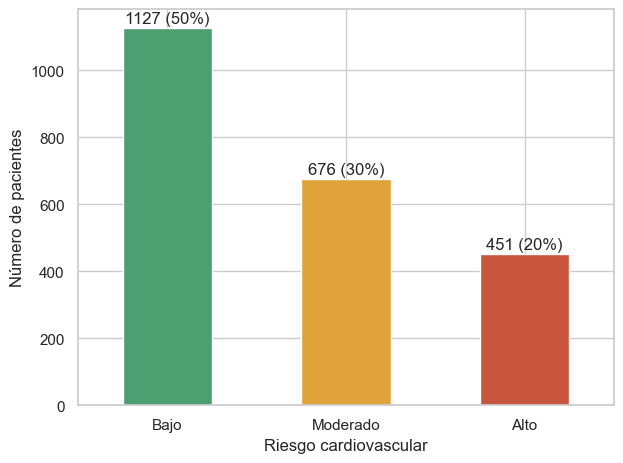

In [9]:
conteo = df[TARGET].value_counts().sort_index()
print((conteo / len(df) * 100).round(2))
print("Ratio mayoritaria / minoritaria:", round(conteo.max() / conteo.min(), 2))

ax = conteo.rename(index=CLASS_NAMES).plot(kind="bar", rot=0,
                                           color=[COLORES_CLASE[k] for k in conteo.index])
for i, v in enumerate(conteo):
    ax.text(i, v + 15, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_xlabel("Riesgo cardiovascular")
ax.set_ylabel("Número de pacientes")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "distribucion_clases.png", dpi=150)
plt.show()

Las clases están desbalanceadas (50 / 30 / 20 %) y la que menos pacientes tiene es justo la de riesgo alto, que es la más importante de detectar. Por eso la accuracy no nos va a servir como métrica principal.

## 4. Variables numéricas: distribución, asimetría y outliers

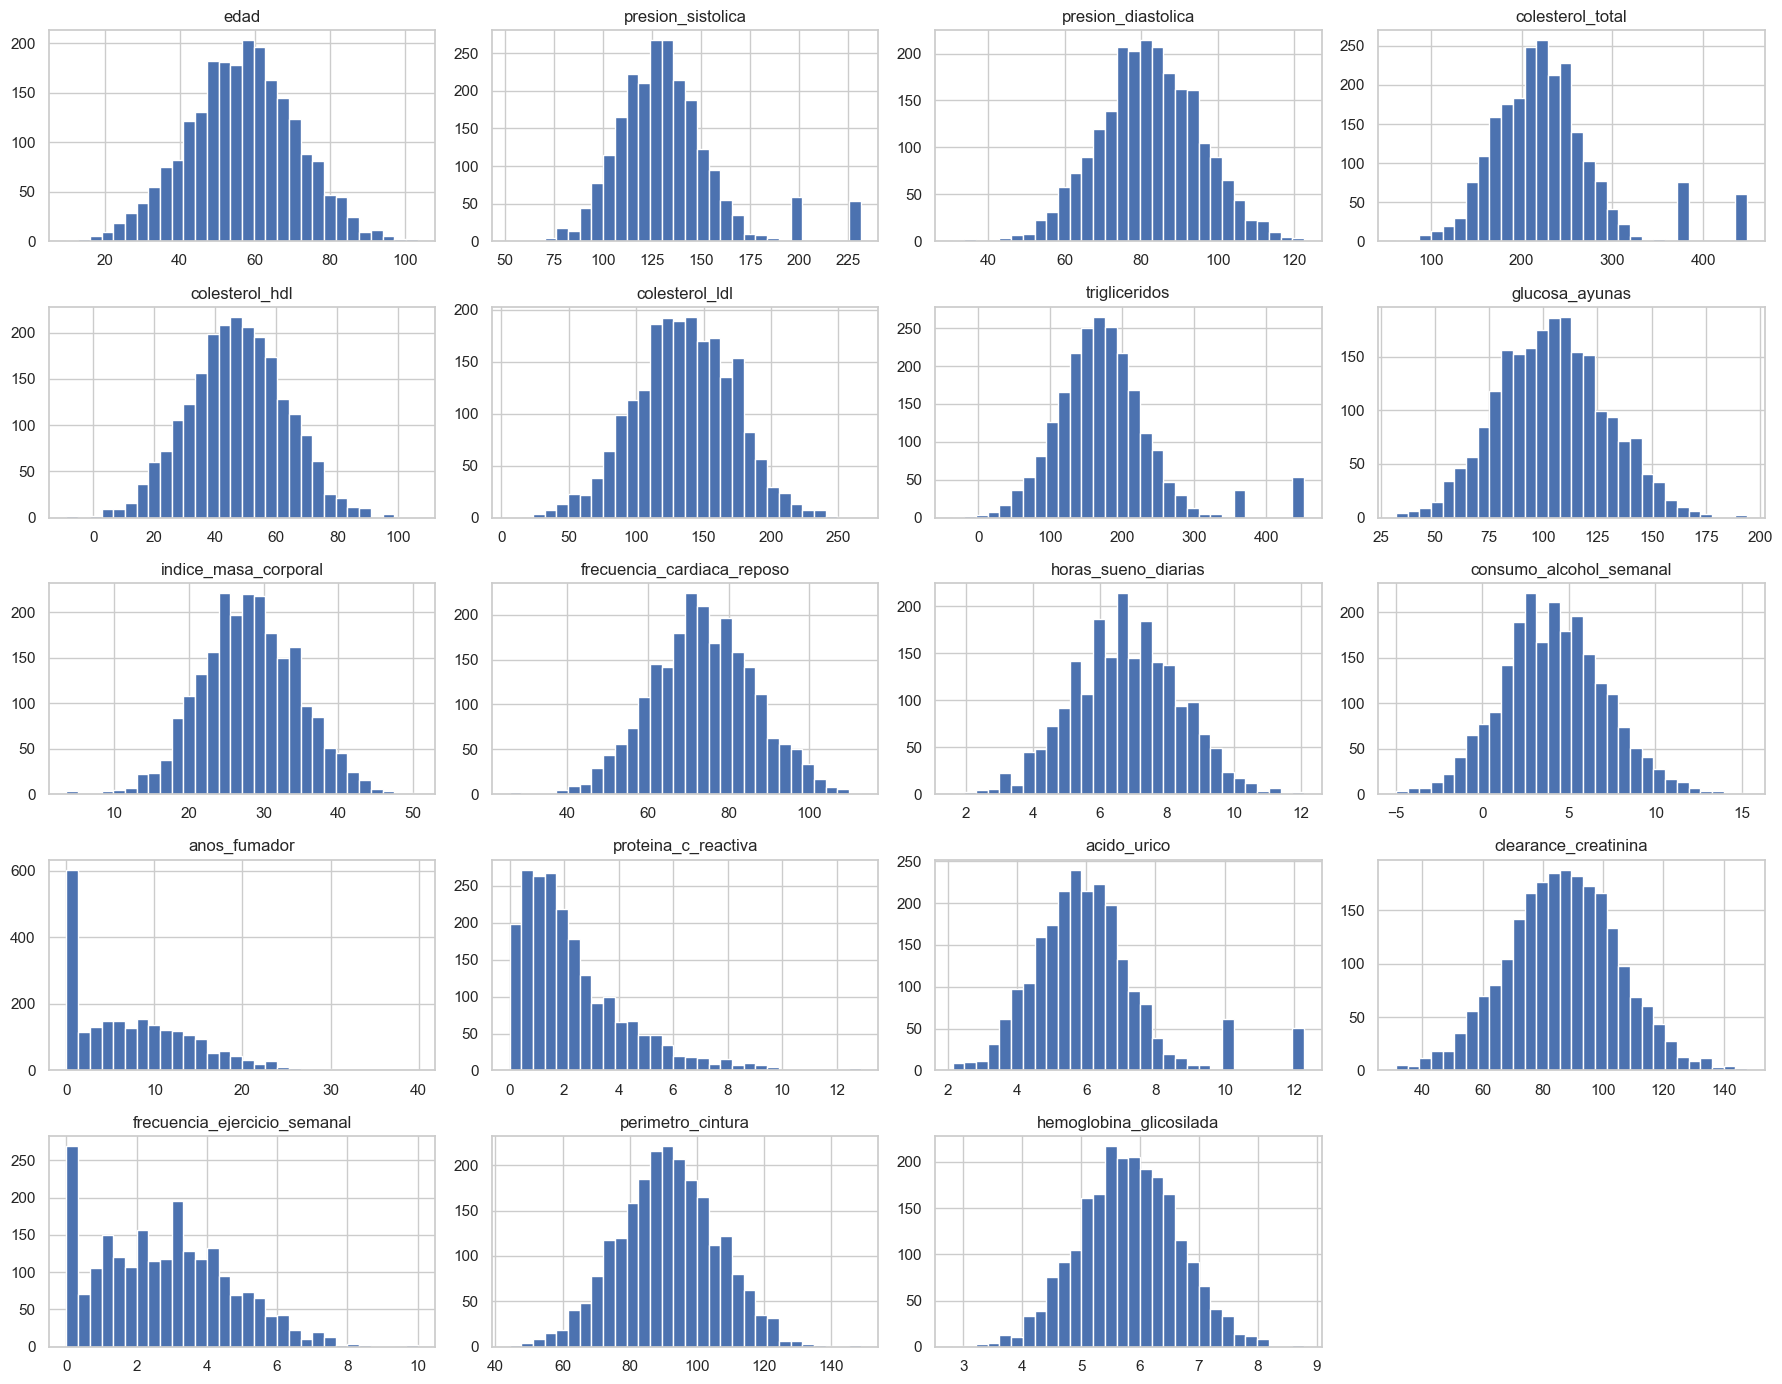

In [10]:
df[NUMERIC_FEATURES].hist(bins=30, figsize=(18, 14))
plt.tight_layout()
plt.savefig(RESULTS_DIR / "histogramas_numericas.png", dpi=150)
plt.show()

Miramos el rango y la asimetría de cada variable:

In [11]:
resumen_num = pd.DataFrame({
    "min": df[NUMERIC_FEATURES].min(),
    "max": df[NUMERIC_FEATURES].max(),
    "rango": df[NUMERIC_FEATURES].max() - df[NUMERIC_FEATURES].min(),
    "desv_tipica": df[NUMERIC_FEATURES].std(),
    "asimetria": df[NUMERIC_FEATURES].skew(),
}).round(2)
resumen_num.sort_values("asimetria", key=abs, ascending=False)

,min,max,rango,desv_tipica,asimetria
proteina_c_reactiva,0.00,12.88,12.88,1.97,1.59
trigliceridos,-35.70,452.70,488.40,72.74,1.32
colesterol_total,61.10,448.59,387.49,62.73,1.29
presion_sistolica,52.20,231.36,179.16,26.93,1.29
acido_urico,2.14,12.29,10.15,1.69,1.28
anos_fumador,0.00,39.90,39.90,6.67,0.72
frecuencia_ejercicio_semanal,0.00,10.00,10.00,1.87,0.39
consumo_alcohol_semanal,-5.00,15.30,20.30,2.99,0.15
glucosa_ayunas,32.00,194.00,162.00,24.94,0.12
colesterol_ldl,6.10,266.70,260.60,36.73,-0.05


In [12]:
# outliers con el criterio del rango intercuartílico (1.5 * IQR)
q1 = df[NUMERIC_FEATURES].quantile(0.25)
q3 = df[NUMERIC_FEATURES].quantile(0.75)
iqr = q3 - q1
fuera = ((df[NUMERIC_FEATURES] < q1 - 1.5 * iqr) | (df[NUMERIC_FEATURES] > q3 + 1.5 * iqr)).sum()
fuera.sort_values(ascending=False)

colesterol_total                147
acido_urico                     120
presion_sistolica               120
trigliceridos                   107
proteina_c_reactiva              89
consumo_alcohol_semanal          25
horas_sueno_diarias              17
presion_diastolica               16
clearance_creatinina             16
perimetro_cintura                15
hemoglobina_glicosilada          14
colesterol_hdl                   14
indice_masa_corporal             14
colesterol_ldl                   13
frecuencia_cardiaca_reposo       12
glucosa_ayunas                   11
edad                             11
frecuencia_ejercicio_semanal     10
anos_fumador                      6
dtype: int64

PCR, triglicéridos, colesterol total, presión sistólica y ácido úrico tienen bastante asimetría a la derecha (entre 1,3 y 1,6) y son las que más outliers tienen. Además las escalas son muy distintas (la PCR va de 0 a 13 y el colesterol llega a 450), lo que afecta a modelos como KNN o la regresión logística.

Ahora vemos cada variable separada por clase:

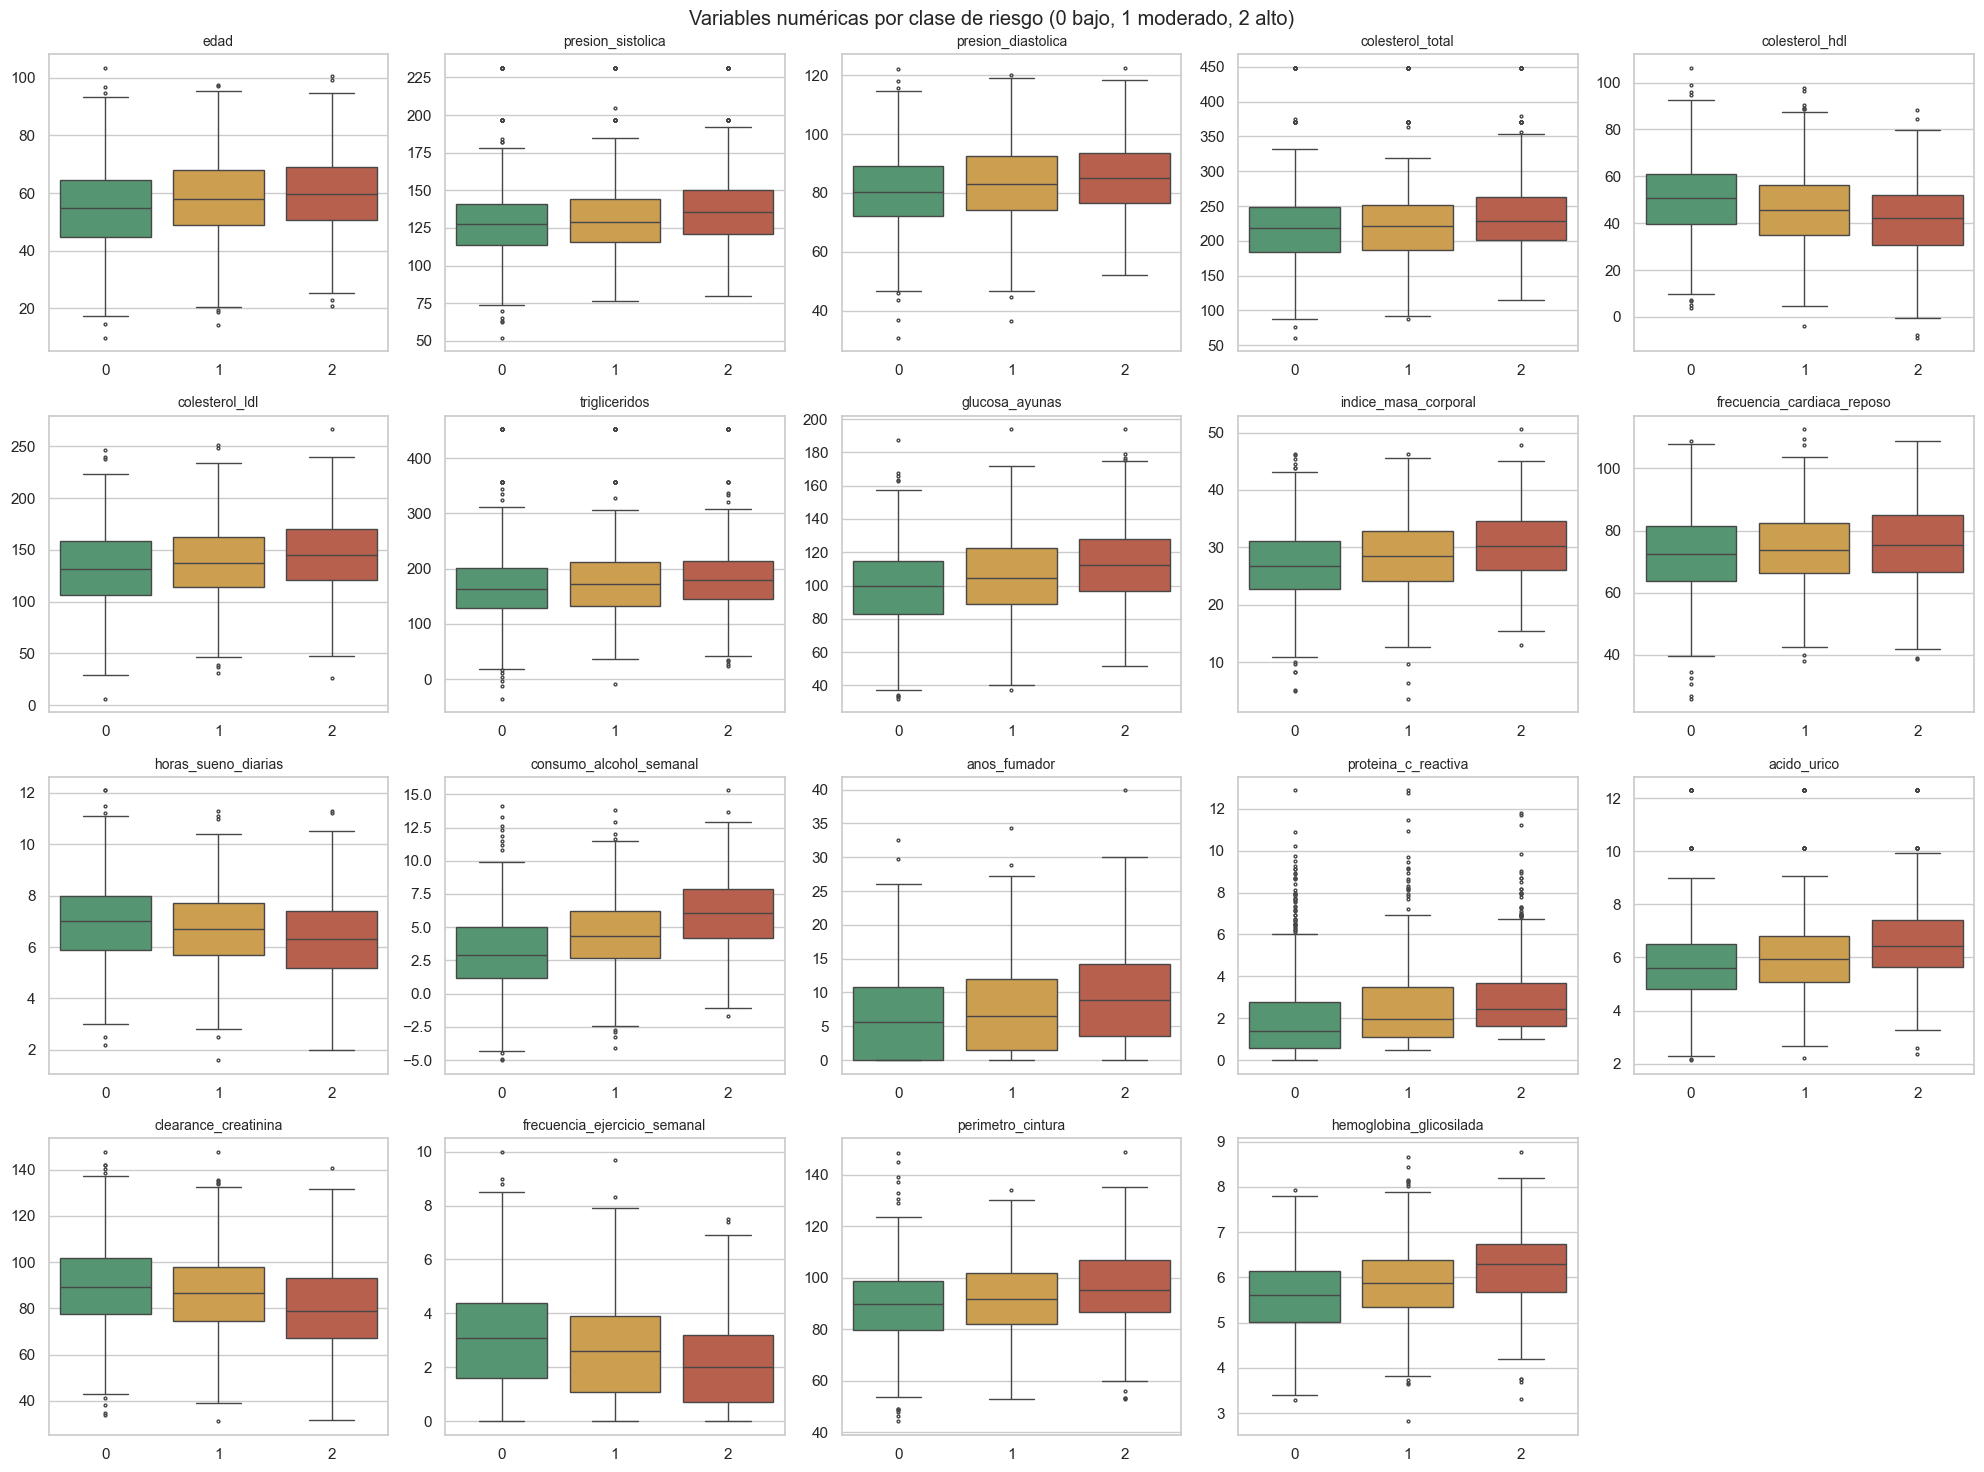

In [13]:
fig, axes = plt.subplots(4, 5, figsize=(20, 15))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=COLORES_CLASE,
                legend=False, ax=ax, fliersize=2)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[len(NUMERIC_FEATURES):]:
    ax.remove()
fig.suptitle("Variables numéricas por clase de riesgo (0 bajo, 1 moderado, 2 alto)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "boxplots_por_clase.png", dpi=150)
plt.show()

## 5. Valores imposibles según rangos clínicos

Con el IQR salen los valores raros, pero no distingue entre un valor raro y uno que directamente no puede existir. Por ejemplo, en el `describe()` hay consumos de alcohol negativos, HDL negativo o pacientes que hacen ejercicio 10 días a la semana.

Para detectarlos hemos definido en `src/reglas_clinicas.py` unos rangos mínimos y máximos para cada variable. Hemos intentado que sean amplios, para marcar solo lo que es imposible o un error claro, y no los valores extremos que sí pueden darse en un paciente. Además añadimos dos reglas que comparan variables:
- la diastólica no puede ser mayor o igual que la sistólica
- los años fumando no pueden ser más que `edad - 10`

Lo ponemos en un archivo aparte porque en el preprocesamiento vamos a usar las mismas reglas.

In [14]:
mascara = mascara_valores_imposibles(df)
reglas = pd.DataFrame(RANGOS_CLINICOS, index=["min_admisible", "max_admisible"]).T
tabla_imposibles = reglas.assign(
    min_observado=df[NUMERIC_FEATURES].min(),
    max_observado=df[NUMERIC_FEATURES].max(),
    n_imposibles=mascara.sum(),
    porcentaje=(mascara.mean() * 100).round(2),
)
tabla_imposibles = tabla_imposibles[tabla_imposibles["n_imposibles"] > 0].sort_values("n_imposibles", ascending=False)
tabla_imposibles.to_csv(RESULTS_DIR / "tabla_valores_imposibles.csv")

print("Valores imposibles en total:", int(mascara.values.sum()))
print("Pacientes con al menos un valor imposible:", mascara.any(axis=1).sum())
print("Negativos:", {c: int((df[c] < 0).sum()) for c in NUMERIC_FEATURES if (df[c] < 0).any()})
tabla_imposibles

Valores imposibles en total: 392
Pacientes con al menos un valor imposible: 325
Negativos: {'colesterol_hdl': 4, 'trigliceridos': 4, 'consumo_alcohol_semanal': 177}


,min_admisible,max_admisible,min_observado,max_observado,n_imposibles,porcentaje
consumo_alcohol_semanal,0.0,NaN,-5.00,15.30,177,7.85
presion_sistolica,60.0,260.0,52.20,231.36,44,1.95
presion_diastolica,30.0,150.0,30.80,122.50,44,1.95
frecuencia_ejercicio_semanal,0.0,7.0,0.00,10.00,41,1.82
colesterol_hdl,10.0,150.0,-8.80,106.30,20,0.89
anos_fumador,0.0,NaN,0.00,39.90,18,0.80
indice_masa_corporal,12.0,70.0,3.60,50.60,13,0.58
trigliceridos,20.0,2000.0,-35.70,452.70,10,0.44
glucosa_ayunas,40.0,600.0,32.00,194.00,6,0.27
perimetro_cintura,50.0,200.0,44.20,148.90,6,0.27


El caso más grande es el alcohol, con 177 valores negativos. Hemos decidido tratarlos como nulos y no ponerlos a 0, porque poner 0 sería decir que el paciente no bebe y eso no lo sabemos. Además el alcohol es de las variables más relacionadas con el riesgo (sección 11), así que meter 177 ceros falsos podría afectar bastante.

Si todos estos valores pasan a ser nulos, las filas incompletas aumentan bastante:

In [15]:
con_nulos_tras_anular = (df[NUMERIC_FEATURES].isna() | mascara).any(axis=1)
print(f"Filas con algún nulo original: {df.isna().any(axis=1).sum()}")
print(f"Filas con algún nulo o valor imposible: {con_nulos_tras_anular.sum()} "
      f"({con_nulos_tras_anular.mean() * 100:.1f} %)")

Filas con algún nulo original: 533
Filas con algún nulo o valor imposible: 772 (34.3 %)


Más de un tercio de los pacientes tendría algún dato que falta, así que eliminar filas no es una opción y habrá que imputar.

## 6. Valores recortados

En los histogramas nos llamó la atención que algunas variables tienen un pico justo en el valor máximo. Contamos cuántos pacientes tienen exactamente el máximo o el mínimo de cada variable:

In [16]:
filas = []
for col in NUMERIC_FEATURES:
    n_max = (df[col] == df[col].max()).sum()
    n_min = (df[col] == df[col].min()).sum()
    filas.append({"variable": col, "max": df[col].max(), "n_en_max": n_max,
                  "p99": round(df[col].quantile(0.99), 2), "min": df[col].min(), "n_en_min": n_min})
recortes = pd.DataFrame(filas).set_index("variable")
recortes[(recortes["n_en_max"] > 5) | (recortes["n_en_min"] > 5)]

,max,n_en_max,p99,min,n_en_min
variable,,,,,
presion_sistolica,231.36,53,231.36,52.20,1
colesterol_total,448.59,61,448.59,61.10,1
trigliceridos,452.70,54,452.70,-35.70,1
anos_fumador,39.90,1,24.35,0.00,503
acido_urico,12.29,51,12.29,2.14,1
frecuencia_ejercicio_semanal,10.00,1,7.40,0.00,204


En presión sistólica, colesterol total, triglicéridos y ácido úrico hay más de 50 pacientes con exactamente el mismo valor máximo, y ese valor coincide con el percentil 99. Parece que los datos se recortaron por arriba antes de dárnoslos, así que hemos perdido la información de los valores más altos. No se puede recuperar, pero lo tenemos en cuenta como limitación.

Los ceros de `anos_fumador` y `frecuencia_ejercicio_semanal` son normales (gente que no fuma o que no hace ejercicio).

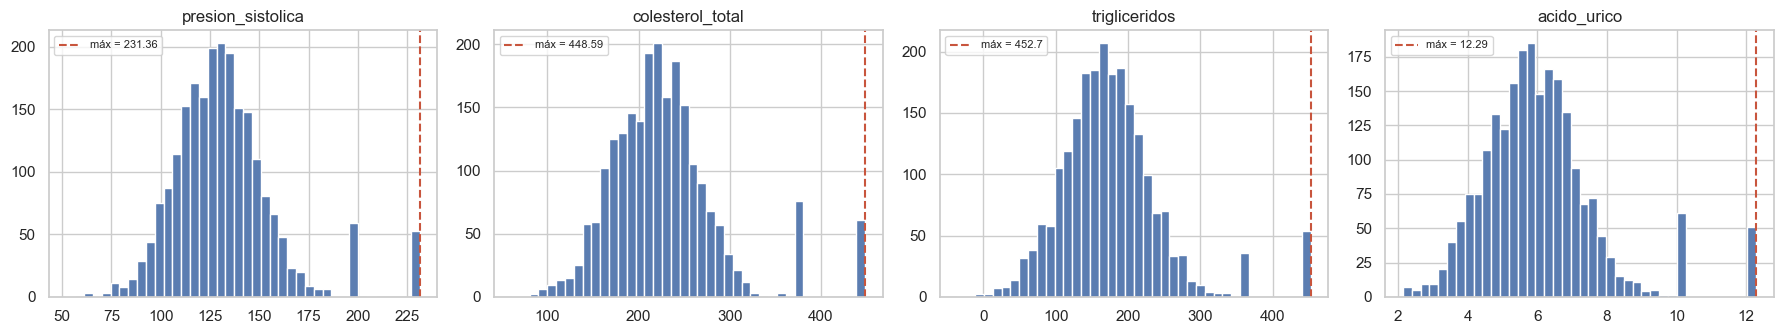

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, ["presion_sistolica", "colesterol_total", "trigliceridos", "acido_urico"]):
    ax.hist(df[col].dropna(), bins=40, color="#5B7DB1")
    ax.axvline(df[col].max(), color="#C8553D", ls="--", label=f"máx = {df[col].max()}")
    ax.set_title(col)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "valores_recortados.png", dpi=150)
plt.show()

## 7. Varianza casi cero

Como vimos en el tema 1, una variable tiene varianza casi cero si el ratio entre el valor más frecuente y el segundo es mayor que 19 y tiene menos de un 10 % de valores únicos.

In [18]:
filas = []
for col in df.columns.drop(TARGET):
    vc = df[col].value_counts()
    filas.append({"variable": col,
                  "ratio_frecuencias": round(vc.iloc[0] / vc.iloc[1], 2),
                  "pct_valores_unicos": round(df[col].nunique() / len(df) * 100, 2)})
nzv = pd.DataFrame(filas).set_index("variable")
nzv["varianza_casi_cero"] = (nzv["ratio_frecuencias"] > 19) & (nzv["pct_valores_unicos"] < 10)
print("Variables con varianza casi cero:", nzv.index[nzv["varianza_casi_cero"]].tolist())
nzv.sort_values("ratio_frecuencias", ascending=False).head(8)

Variables con varianza casi cero: []


,ratio_frecuencias,pct_valores_unicos,varianza_casi_cero
variable,,,
anos_fumador,29.59,11.54,False
diabetes_mellitus,3.39,0.09,False
frecuencia_ejercicio_semanal,3.29,3.86,False
fumador_actual,2.79,0.09,False
tratamiento_estatinas,2.68,0.09,False
antecedentes_familiares_tipo,2.07,0.18,False
uso_antihipertensivos,1.86,0.09,False
hipertension_previa,1.73,0.09,False


Ninguna variable cumple las dos condiciones, así que no hay que quitar ninguna por este motivo.

## 8. Variables binarias y categóricas

In [19]:
for col in BINARY_FEATURES + CATEGORICAL_FEATURES:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


fumador_actual
fumador_actual
0    1659
1     595
Name: count, dtype: int64

hipertension_previa
hipertension_previa
0    1427
1     827
Name: count, dtype: int64

diabetes_mellitus
diabetes_mellitus
0    1741
1     513
Name: count, dtype: int64

tratamiento_estatinas
tratamiento_estatinas
0    1641
1     613
Name: count, dtype: int64

uso_antihipertensivos
uso_antihipertensivos
0    1467
1     787
Name: count, dtype: int64

tipo_alimentacion
tipo_alimentacion
Occidental               881
Mediterránea             706
Baja en carbohidratos    349
Vegetariana              318
Name: count, dtype: int64

nivel_actividad
nivel_actividad
Ligeramente activo      695
Sedentario              687
Moderadamente activo    563
Muy activo              309
Name: count, dtype: int64

antecedentes_familiares_tipo
antecedentes_familiares_tipo
Ninguno    1072
Materno     517
Paterno     477
Ambos       188
Name: count, dtype: int64


Para ver si hay categorías mal escritas pasamos todo a minúsculas, quitamos espacios y tildes, y comparamos el número de categorías antes y después. También comprobamos que no aparezcan valores que no estén en el enunciado.

In [20]:
def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto).strip().lower())
    return "".join(c for c in texto if not unicodedata.combining(c))

esperadas_cat = {
    "tipo_alimentacion": {"Mediterránea", "Occidental", "Vegetariana", "Baja en carbohidratos"},
    "nivel_actividad": {"Sedentario", "Ligeramente activo", "Moderadamente activo", "Muy activo"},
    "antecedentes_familiares_tipo": {"Ninguno", "Materno", "Paterno", "Ambos"},
}
for col, validas in esperadas_cat.items():
    observadas = set(df[col].dropna().unique())
    print(f"{col}: {len(observadas)} categorías en bruto, "
          f"{df[col].dropna().map(normalizar).nunique()} tras normalizar; "
          f"no previstas en el enunciado: {observadas - validas or 'ninguna'}")
for col in BINARY_FEATURES:
    print(f"{col}: valores {sorted(df[col].unique())}")

tipo_alimentacion: 4 categorías en bruto, 4 tras normalizar; no previstas en el enunciado: ninguna
nivel_actividad: 4 categorías en bruto, 4 tras normalizar; no previstas en el enunciado: ninguna
antecedentes_familiares_tipo: 4 categorías en bruto, 4 tras normalizar; no previstas en el enunciado: ninguna
fumador_actual: valores [np.int64(0), np.int64(1)]
hipertension_previa: valores [np.int64(0), np.int64(1)]
diabetes_mellitus: valores [np.int64(0), np.int64(1)]
tratamiento_estatinas: valores [np.int64(0), np.int64(1)]
uso_antihipertensivos: valores [np.int64(0), np.int64(1)]


Las categorías están bien escritas y las binarias solo tienen 0 y 1. Ahora vemos cómo se reparten las clases dentro de cada categoría:

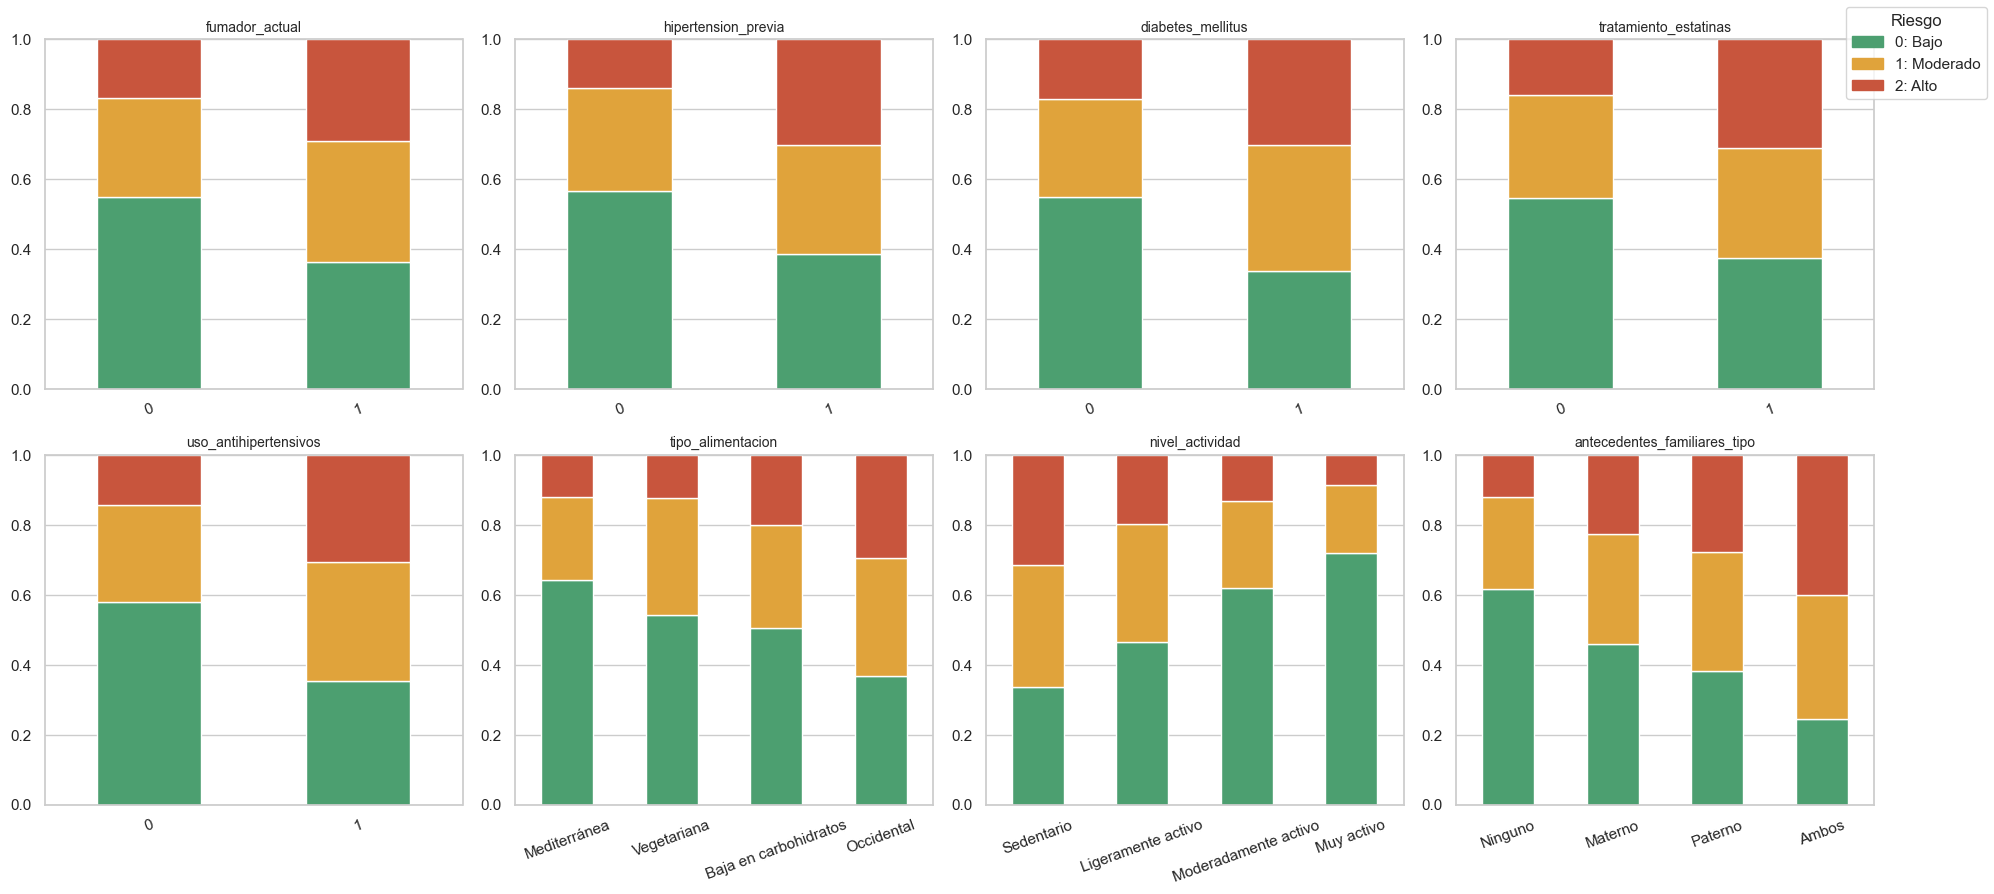

In [21]:
orden_cat = {
    "nivel_actividad": ["Sedentario", "Ligeramente activo", "Moderadamente activo", "Muy activo"],
    "antecedentes_familiares_tipo": ["Ninguno", "Materno", "Paterno", "Ambos"],
    "tipo_alimentacion": ["Mediterránea", "Vegetariana", "Baja en carbohidratos", "Occidental"],
}
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, BINARY_FEATURES + CATEGORICAL_FEATURES):
    prop = pd.crosstab(df[col], df[TARGET], normalize="index")
    if col in orden_cat:
        prop = prop.loc[orden_cat[col]]
    prop.plot(kind="bar", stacked=True, ax=ax, legend=False,
              color=[COLORES_CLASE[k] for k in prop.columns], rot=20)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORES_CLASE[k]) for k in CLASS_NAMES]
fig.legend(handles, [f"{k}: {v}" for k, v in CLASS_NAMES.items()], loc="upper right", title="Riesgo")
plt.tight_layout(rect=(0, 0, 0.95, 1))
plt.savefig(RESULTS_DIR / "categoricas_por_clase.png", dpi=150)
plt.show()

Se ven diferencias claras entre categorías. En `nivel_actividad` el riesgo alto baja a medida que la persona es más activa, así que tiene sentido codificarla como ordinal. En antecedentes familiares el riesgo alto pasa del 12 % (ninguno) al 40 % (ambos padres).

## 9. Incoherencias lógicas entre variables

Hay variables que deberían ser coherentes entre sí, así que comprobamos algunas combinaciones que no tienen sentido. Para la diabetes usamos los criterios habituales: glucosa en ayunas ≥ 126 mg/dL o HbA1c ≥ 6,5 %.

In [22]:
d = df
reglas_logicas = {
    "Diastólica >= sistólica": d.presion_diastolica >= d.presion_sistolica,
    "HDL + LDL > colesterol total": (d.colesterol_hdl + d.colesterol_ldl) > d.colesterol_total,
    "No fumador con años de fumador > 0": (d.fumador_actual == 0) & (d.anos_fumador > 0),
    "No fumador con años de fumador > 10": (d.fumador_actual == 0) & (d.anos_fumador > 10),
    "Fumador actual con 0 años de fumador": (d.fumador_actual == 1) & (d.anos_fumador == 0),
    f"Años de fumador > edad - {EDAD_MIN_INICIO_TABACO}": d.anos_fumador > d.edad - EDAD_MIN_INICIO_TABACO,
    "No diabético con glucosa >= 126 o HbA1c >= 6,5": (d.diabetes_mellitus == 0) & ((d.glucosa_ayunas >= 126) | (d.hemoglobina_glicosilada >= 6.5)),
    "Diabético con glucosa < 100 y HbA1c < 5,7": (d.diabetes_mellitus == 1) & (d.glucosa_ayunas < 100) & (d.hemoglobina_glicosilada < 5.7),
    "Antihipertensivos sin hipertensión previa": (d.uso_antihipertensivos == 1) & (d.hipertension_previa == 0),
    "Sedentario con >= 5 días de ejercicio": (d.nivel_actividad == "Sedentario") & (d.frecuencia_ejercicio_semanal >= 5),
    "Muy activo con 0 días de ejercicio": (d.nivel_actividad == "Muy activo") & (d.frecuencia_ejercicio_semanal == 0),
}
tabla_incoherencias = pd.DataFrame({
    "n_pacientes": {k: int(v.sum()) for k, v in reglas_logicas.items()},
    "porcentaje": {k: round(v.mean() * 100, 2) for k, v in reglas_logicas.items()},
})
tabla_incoherencias.to_csv(RESULTS_DIR / "tabla_incoherencias_logicas.csv")
tabla_incoherencias

,n_pacientes,porcentaje
Diastólica >= sistólica,44,1.95
HDL + LDL > colesterol total,559,24.80
No fumador con años de fumador > 0,1279,56.74
No fumador con años de fumador > 10,533,23.65
Fumador actual con 0 años de fumador,123,5.46
Años de fumador > edad - 10,18,0.80
"No diabético con glucosa >= 126 o HbA1c >= 6,5",597,26.49
"Diabético con glucosa < 100 y HbA1c < 5,7",98,4.35
Antihipertensivos sin hipertensión previa,478,21.21
Sedentario con >= 5 días de ejercicio,90,3.99


La regla de HDL + LDL solo se puede comprobar en los pacientes que tienen LDL (con NaN la comparación da False). También miramos si el nivel de actividad cuadra con los días de ejercicio:

In [23]:
print("Filas con LDL observado:", df.colesterol_ldl.notna().sum())
df.groupby("nivel_actividad")["frecuencia_ejercicio_semanal"].describe().loc[orden_cat["nivel_actividad"]].round(2)

Filas con LDL observado: 2119


,count,mean,std,min,25%,50%,75%,max
nivel_actividad,,,,,,,,
Sedentario,687.0,2.66,1.89,0.0,1.05,2.6,4.0,8.4
Ligeramente activo,695.0,2.70,1.86,0.0,1.30,2.6,3.9,9.7
Moderadamente activo,563.0,3.01,1.89,0.0,1.50,3.0,4.3,10.0
Muy activo,309.0,2.79,1.83,0.0,1.20,2.8,4.0,7.9


Y comparamos el LDL con el que saldría con la fórmula de Friedewald (LDL ≈ total − HDL − TG/5):

In [24]:
ldl_friedewald = df.colesterol_total - df.colesterol_hdl - df.trigliceridos / 5
observado = df.colesterol_ldl.notna()
print("Correlación LDL observado vs Friedewald:",
      round(np.corrcoef(df.colesterol_ldl[observado], ldl_friedewald[observado])[0, 1], 3))

Correlación LDL observado vs Friedewald: 0.035


Salen muchas incoherencias. En el 26 % de los pacientes con LDL, HDL + LDL es mayor que el colesterol total, cosa que no puede pasar, y el LDL no se parece nada al de Friedewald. Hay muchos no fumadores con años de fumador (algunos podrían ser exfumadores, pero 533 tienen más de 10 años), muchos "no diabéticos" con valores de diabetes, y los días de ejercicio son prácticamente iguales en todos los niveles de actividad.

Estas incoherencias no las vamos a corregir porque no sabemos cuál de las variables es la que está mal. Solo anulamos los dos casos que son imposibles (diastólica ≥ sistólica y años fumando > edad - 10), que ya estaban en la sección 5. El resto lo dejamos como limitación del dataset.

## 10. Correlaciones y redundancia

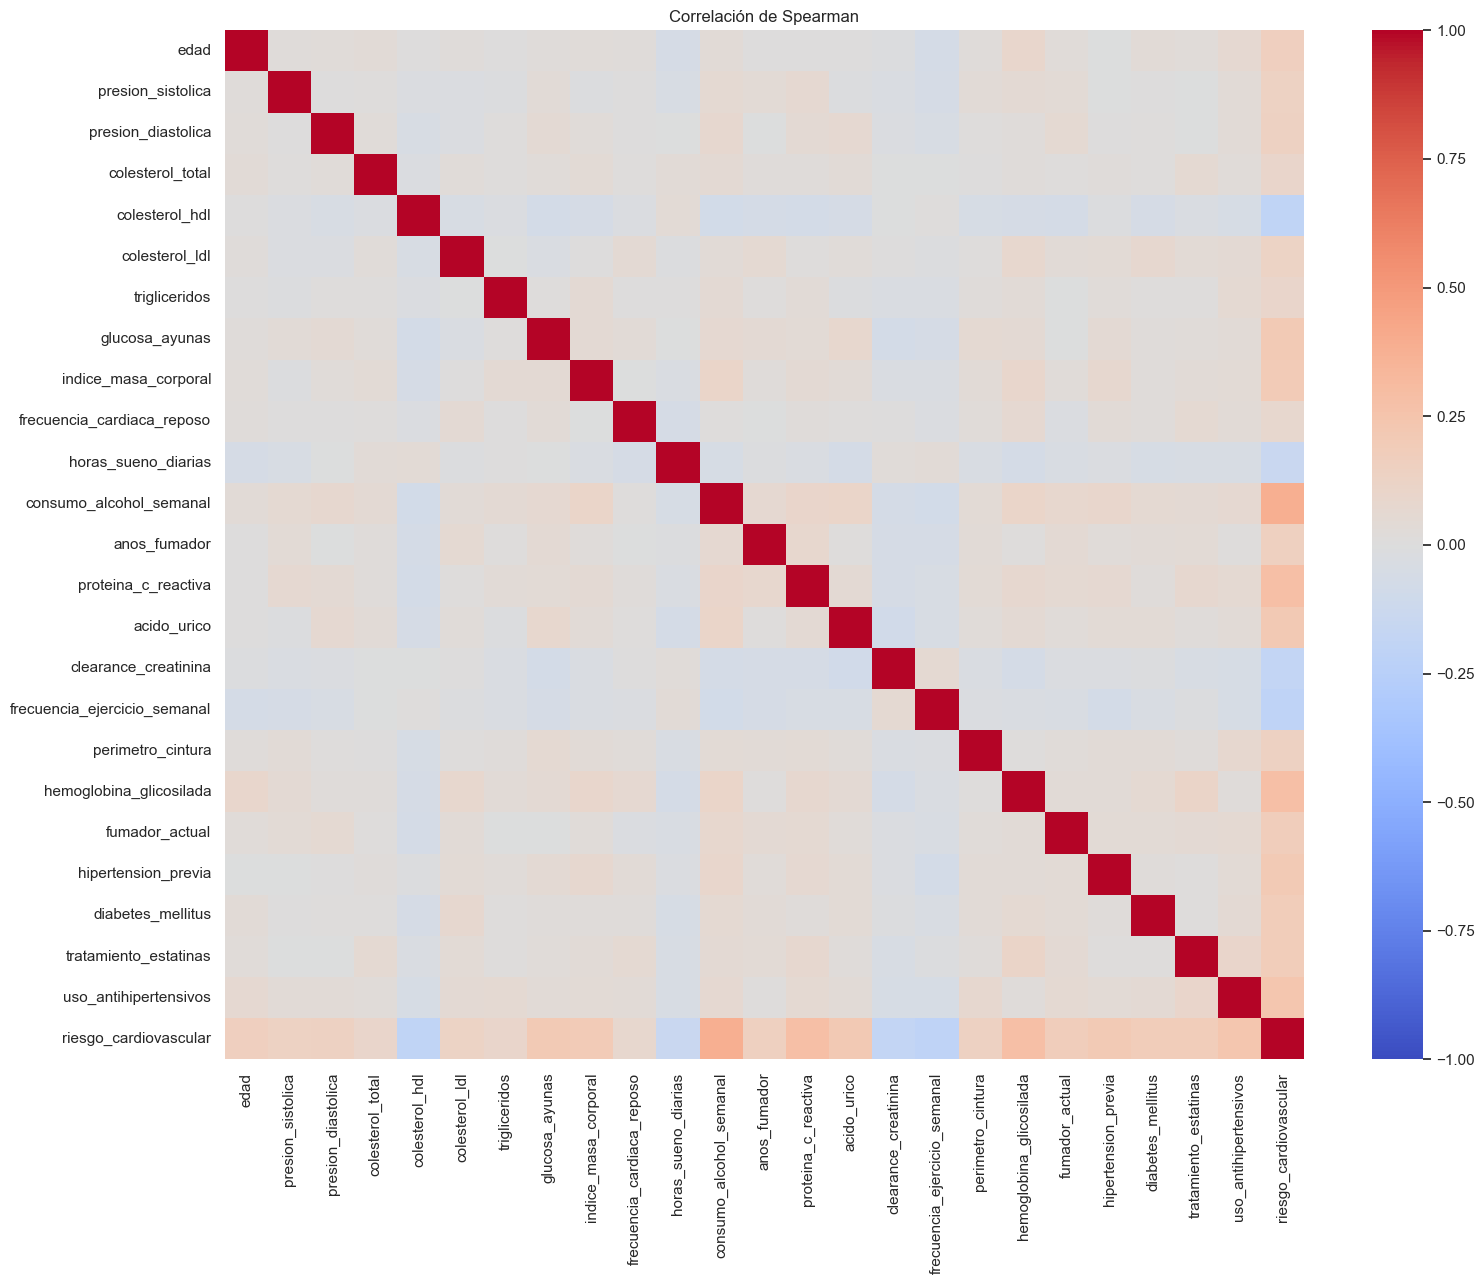

In [25]:
# usamos Spearman porque hay variables asimétricas y binarias
corr = df[NUMERIC_FEATURES + BINARY_FEATURES + [TARGET]].corr(method="spearman")
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "correlaciones.png", dpi=150)
plt.show()

In [26]:
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("rho").to_frame())
pares["abs"] = pares["rho"].abs()
print("Pares con |rho| > 0.5:", (pares["abs"] > 0.5).sum())
pares.sort_values("abs", ascending=False).head(10).drop(columns="abs").round(3)

Pares con |rho| > 0.5: 0


,,rho
consumo_alcohol_semanal,riesgo_cardiovascular,0.388
hemoglobina_glicosilada,riesgo_cardiovascular,0.283
proteina_c_reactiva,riesgo_cardiovascular,0.282
uso_antihipertensivos,riesgo_cardiovascular,0.236
acido_urico,riesgo_cardiovascular,0.213
glucosa_ayunas,riesgo_cardiovascular,0.210
frecuencia_ejercicio_semanal,riesgo_cardiovascular,-0.207
hipertension_previa,riesgo_cardiovascular,0.205
colesterol_hdl,riesgo_cardiovascular,-0.200
indice_masa_corporal,riesgo_cardiovascular,0.196


Miramos también algunos pares que deberían estar relacionados:

In [27]:
esperados = [("presion_sistolica", "presion_diastolica"),
             ("perimetro_cintura", "indice_masa_corporal"),
             ("glucosa_ayunas", "hemoglobina_glicosilada"),
             ("colesterol_total", "colesterol_ldl"),
             ("glucosa_ayunas", "diabetes_mellitus"),
             ("presion_sistolica", "hipertension_previa"),
             ("anos_fumador", "fumador_actual")]
pd.DataFrame([{"par": f"{a} ~ {b}", "rho_spearman": round(corr.loc[a, b], 3)} for a, b in esperados]).set_index("par")

,rho_spearman
par,
presion_sistolica ~ presion_diastolica,0.007
perimetro_cintura ~ indice_masa_corporal,0.038
glucosa_ayunas ~ hemoglobina_glicosilada,0.051
colesterol_total ~ colesterol_ldl,0.026
glucosa_ayunas ~ diabetes_mellitus,0.019
presion_sistolica ~ hipertension_previa,-0.005
anos_fumador ~ fumador_actual,0.052


No hay ningún par con correlación fuerte, así que no hay variables redundantes que quitar. Lo raro es que variables que en la realidad van muy unidas (sistólica y diastólica, cintura e IMC, glucosa y HbA1c) aquí no tienen casi relación. Junto con las incoherencias de la sección 9, esto nos hace pensar que el dataset es sintético o que las variables se generaron por separado.

## 11. Relación de cada variable con la clase

Para las numéricas usamos el test de Kruskal-Wallis (no paramétrico, porque varias variables no son normales) y medimos el tamaño del efecto con épsilon cuadrado. Para las binarias y categóricas usamos chi-cuadrado y la V de Cramér. Como con 2.254 pacientes casi todo sale significativo, nos fijamos sobre todo en el tamaño del efecto.

In [28]:
filas = []
for col in NUMERIC_FEATURES:
    grupos = [df.loc[df[TARGET] == k, col].dropna() for k in sorted(CLASS_NAMES)]
    h, p = stats.kruskal(*grupos)
    n, k = sum(len(g) for g in grupos), len(grupos)
    filas.append({"variable": col, "tipo": "numérica", "test": "Kruskal-Wallis",
                  "estadistico": h, "p_valor": p, "efecto": (h - k + 1) / (n - k), "medida_efecto": "epsilon²",
                  "mediana_0": grupos[0].median(), "mediana_1": grupos[1].median(), "mediana_2": grupos[2].median()})
for col in BINARY_FEATURES + CATEGORICAL_FEATURES:
    tabla = pd.crosstab(df[col], df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    filas.append({"variable": col, "tipo": "binaria" if col in BINARY_FEATURES else "categórica",
                  "test": "Chi²", "estadistico": chi2, "p_valor": p, "efecto": v, "medida_efecto": "V de Cramér"})
relacion = pd.DataFrame(filas).set_index("variable").sort_values(["medida_efecto", "efecto"], ascending=[True, False])
relacion.to_csv(RESULTS_DIR / "tabla_relacion_clase.csv")
print("Variables con p < 0.05:", (relacion["p_valor"] < 0.05).sum(), "de", len(relacion))
relacion.round(4)

Variables con p < 0.05: 27 de 27


,tipo,test,estadistico,p_valor,efecto,medida_efecto,mediana_0,mediana_1,mediana_2
variable,,,,,,,,,
uso_antihipertensivos,binaria,Chi²,126.8209,0.0000,0.2372,V de Cramér,NaN,NaN,NaN
hipertension_previa,binaria,Chi²,103.6235,0.0000,0.2144,V de Cramér,NaN,NaN,NaN
nivel_actividad,categórica,Chi²,188.5832,0.0000,0.2045,V de Cramér,NaN,NaN,NaN
antecedentes_familiares_tipo,categórica,Chi²,167.0092,0.0000,0.1925,V de Cramér,NaN,NaN,NaN
tratamiento_estatinas,binaria,Chi²,78.4772,0.0000,0.1866,V de Cramér,NaN,NaN,NaN
diabetes_mellitus,binaria,Chi²,77.9264,0.0000,0.1859,V de Cramér,NaN,NaN,NaN
tipo_alimentacion,categórica,Chi²,146.4091,0.0000,0.1802,V de Cramér,NaN,NaN,NaN
fumador_actual,binaria,Chi²,71.3190,0.0000,0.1779,V de Cramér,NaN,NaN,NaN
consumo_alcohol_semanal,numérica,Kruskal-Wallis,346.4525,0.0000,0.1530,epsilon²,2.90,4.300,6.10


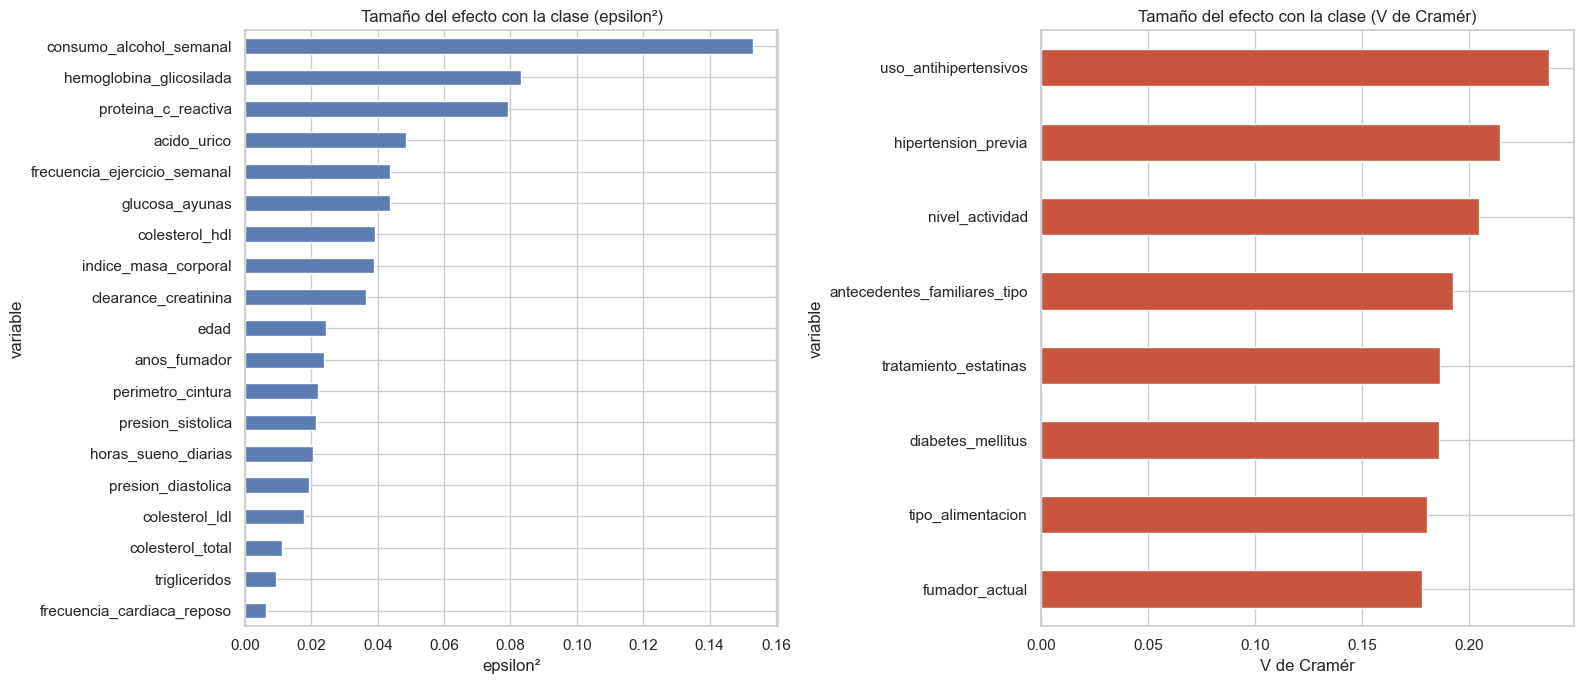

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, medida, color in zip(axes, ["epsilon²", "V de Cramér"], ["#5B7DB1", "#C8553D"]):
    sub = relacion[relacion["medida_efecto"] == medida]["efecto"].sort_values()
    sub.plot(kind="barh", ax=ax, color=color)
    ax.set_title(f"Tamaño del efecto con la clase ({medida})")
    ax.set_xlabel(medida)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "relacion_variables_clase.png", dpi=150)
plt.show()

Las 27 variables salen significativas, pero los efectos son pequeños. Las que más se relacionan con el riesgo son las binarias y categóricas (antihipertensivos, hipertensión, nivel de actividad y antecedentes, con V entre 0,18 y 0,24). De las numéricas destacan el alcohol, la HbA1c y la PCR. Al estar la información repartida entre muchas variables, no vamos a quitar ninguna.

## 12. Problemáticas identificadas

Resumen de los problemas que hemos encontrado:

1. **Valores ausentes**: hay nulos en sueño (180), PCR (157), LDL (135) y glucosa (112). Afectan al 23,6 % de las filas y no dependen de la clase.
2. **Valores imposibles**: 392 valores en 325 pacientes que no tienen sentido clínico (177 alcohol negativo, 44 diastólica ≥ sistólica, 41 más de 7 días de ejercicio, 20 HDL < 10, 18 más años fumando que edad - 10, 13 IMC < 12, etc.). Si los pasamos a nulos, el 34,3 % de las filas queda incompleto.
3. **Valores recortados**: sistólica, colesterol total, triglicéridos y ácido úrico están cortados en el percentil 99 (entre 51 y 61 pacientes con el mismo máximo).
4. **Outliers y asimetría**: PCR, triglicéridos, colesterol total, sistólica y ácido úrico con asimetría entre 1,3 y 1,6.
5. **Escalas distintas**: unas variables van de 0 a 10 y otras llegan a cientos.
6. **Desbalanceo**: 50 / 30 / 20 %, y la clase de riesgo alto es la minoritaria.
7. **Incoherencias lógicas**: HDL + LDL > total en el 26 % de los pacientes con LDL, no fumadores con años de fumador, no diabéticos con glucosa o HbA1c de diabetes, antihipertensivos sin hipertensión, etc.
8. **Variables categóricas**: están bien escritas pero hay que codificarlas (`nivel_actividad` es ordinal y las otras dos nominales). Al haber variables numéricas, binarias y categóricas mezcladas, hay que tenerlo en cuenta si usamos SMOTE.
9. **Poca relación entre variables**: no hay correlaciones fuertes ni siquiera entre variables que deberían estar relacionadas, y todas tienen una relación pequeña con la clase.

No hay filas duplicadas, ninguna variable tiene varianza casi cero y las categóricas no tienen errores de escritura.

Por todo lo visto en las secciones 9 y 10 creemos que el dataset es en buena parte sintético, lo que habrá que tener en cuenta al sacar conclusiones clínicas de los modelos.